# Expected value gets more expensive check

Price per unit of expected voting power must increase as level does.

In [32]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [34]:
# Add project source directory to import path.
import sys
import os
from pathlib import Path

parent_dir = str(os.path.join(Path.cwd().parent, 'src'))

if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)

# Imports.
import math
import numpy as np
import matplotlib.pyplot as plt
import fvopn_simulations as fvopn
from scipy.interpolate import make_interp_spline

In [35]:
rng = np.random.default_rng(42)

size = 1000 # Number of nodes.
alpha = 5 # Root slots.
k = 20 # Multiplication factor.
levels = math.ceil(math.log(size * (k - 1) / alpha + 1, k))
budgets=rng.beta(.5, 8, size) # Random generated budgets.

conf = fvopn.VoteAuctionModelV2Config(
    budgets=budgets,
    root_slots=alpha,
    multiplication_factor=k,
)

model = fvopn.VoteAuctionModelV2(conf, rng)

In [146]:
def graph_fn(fn):
    fn_vec = np.vectorize(fn)

    xpoints = np.arange(1, 10)
    ypoints = fn_vec(xpoints)

    # Create the spline object
    spline_obj = make_interp_spline(xpoints, ypoints)

    # Evaluate at new points
    x_smooth = np.linspace(xpoints.min(), xpoints.max(), 300)
    y_smooth = spline_obj(x_smooth)

    plt.plot(x_smooth, y_smooth)

In [37]:
g = lambda x: 1 - 1 / (k**(x-1))

f = lambda x: g(x) / (alpha * k**(x-1))

def c(n):
    x = 0
    
    for i in range(levels-n):
        x += g(i+n+1)

    return x / (alpha * (k ** (n + 1) - 1) / (k - 1))

E = lambda x: 1 - f(x) + c(x)

def p(n: int):
        if n == 1:
            return 1

        return p(n - 1) / (E(n) / p(n - 1)/2)

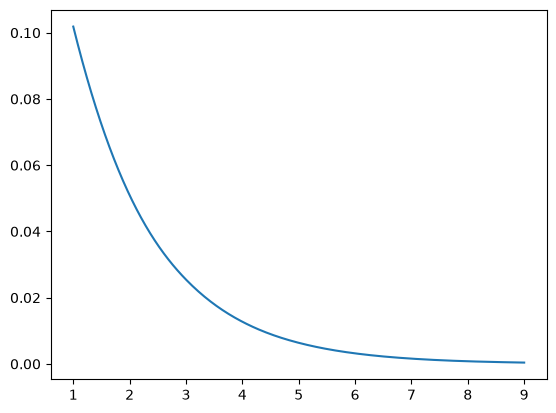

In [156]:
graph_fn(lambda x: model.expected_value(x) * model.level_price(x))
#graph_fn(lambda x: model.expected_value(x))
#graph_fn(lambda x: model.stolen_from_level(x))
#graph_fn(lambda x: model.level_price(x))